# Notebook 1 · Literatura, aprimoramento e validação multiambientes · v10

**CIV2155 · FNDE Tipo 2 · Arquitetura ARQ-DTV R03 · 30/10/2026.**

Esta revisão responde à avaliação do acervo disponível em `01_Referencias` e testa as propostas pertinentes ao código. O inventário inicial contém **73 PDFs e 63 conteúdos únicos por hash**: seis pranchas de projeto e **57 documentos bibliográficos/técnicos**. Manuais e documentação não foram apresentados como artigos científicos adicionais. O registro inclui decisão sobre cada documento e sete análises aprofundadas dos métodos selecionados.

Foi feita triagem de todo o acervo, reutilizando catálogos anteriores conferidos por hash e aprofundando método, pressupostos e limitações das propostas relevantes. Não se afirma leitura linear das 1.258 páginas ou reprodução dos experimentos dos 57 documentos. O relatório final permite filtrar o acervo e consultar a justificativa de cada decisão.

**Resultado a reproduzir:** associação em **38 dos 41 espaços**, contra 29 na v09; os 29 BReps anteriormente aceitos e os 74 pares anteriores permanecem preservados. A v10 registra 101 pares ambiente–esquadria. Na mesma amostra de 14 ambientes, são 39 positivos confirmados de 43 referências positivas, uma omissão após execução, três positivos sem resultado por preparo, 37 exclusões corretas e dois negativos não avaliáveis. JA-09 continua indeterminada.

As versões e o grafo anterior são preservados. O código é adaptação específica deste estudo, assistida por IA; as contribuições dos autores, as extensões e as limitações aparecem junto às etapas. A amostra é **intencional e usada no desenvolvimento**, sem teste cego por especialista ou validação em outro edifício.

## Fontes e decisões sobre os métodos

| Fonte | Uso efetivo nesta revisão |
|---|---|
| [Fichter et al. (2021), IFC2SB](https://doi.org/10.26868/25222708.2021.30156), pp. 3–5 | Motivação para ampliar o preparo antes de exigir o sólido fechado; fonte parcial de recortes/ancestralidade já utilizada. Healing com OCCT/guardas é adaptação do estudo, não portabilidade integral do outer hull. |
| [Kiavarz et al. (2023)](https://doi.org/10.3390/buildings13020350), §§4.2.2–4.4 | Núcleo de interfaces por projeção, orientação, raios e sondas preservado. `BoundedBy` literal continua sendo uma pré-condição não atendida pelo arquivo. |
| [Ying e Lee (2021), múltiplas representações](https://doi.org/10.1016/j.autcon.2021.103659), §§3.1, 4.3 | Separar BRep, faces poligonais e pré-filtro. Projeção planar controlada é adaptação própria; AABB/cache já existiam e não são anunciados como novidade. |
| [Ying e Lee (2021), validação de limites](https://doi.org/10.1016/j.autcon.2021.103724), §§4.3–4.4 | Auditoria de sobreposição, proveniência e balanço de áreas; não implementação das 38 regras completas. |
| [Lilis et al. (2026), diagnóstico geométrico](https://doi.org/10.1016/j.jobe.2026.115667), §§4–5 | Diferenciar falhas de superfície, colisões e definição do espaço. Diagnóstico condicionado ao método não equivale a reparação automática. |
| [Lilis et al. (2025), GRC](https://doi.org/10.1016/j.autcon.2025.106081), §§3.2–3.5 | Confirmar contenção volumétrica ou registrar inconclusão; OCP atual do estudo, não execução integral do GRC/BSP. |
| [Wang, Zhang e Yan (2024), SHACL](https://doi.org/10.1016/j.autcon.2024.105293) | Contratos próprios do resultado v10, com violações deliberadas; não transplantar regras ifcOWL para LBD. |
| [Ham (2026), XeoBIM](https://doi.org/10.3390/buildings16153086), §§3.2–3.4 | Ensaio por cortes 2D, separado e sem fallback por caixa; rejeitado como substituto do núcleo 3D. |
| [Krijnen et al. (2020)](https://doi.org/10.46421/2706-6568.37.2020.paper008) | Formalização de tolerância/predicados e ensaios anteriores preservados. CGAL/Nef não reexecutado para todo o edifício; candidatos com folga não são convertidos em contatos. |
| [Lilis et al. (2026), geração por espaços/aberturas](https://doi.org/10.1016/j.autcon.2026.106840) | Vinte controles parciais anteriores repetidos; o fluxo integral não substituiu a rotina, pois requer volumes preparados e sem interseções. |
| [Bonduel et al. (2018), IFCtoLBD](https://ceur-ws.org/Vol-2159/04paper.pdf), [Jäkel et al. (2025)](https://doi.org/10.3390/buildings15050720), [Zhang et al. (2018), BimSPARQL](https://doi.org/10.3233/SW-180297) | Conversão, identidades, validação anterior e representação GEOM preservadas. Java não reexecutado; carregar WKT não ativa automaticamente todas as funções do BimSPARQL. |

[Ciria e Diaz de Garayo (2025)](https://doi.org/10.1088/1742-6596/3140/4/042004) permanece como alternativa de reconstrução por grafo de paredes, sem adotar agregação térmica de cômodos ou perder a correspondência com os IfcSpace. Artigos de IA, navegação, BIM–GIS, instalações e harmonização foram classificados por sua contribuição específica, sem apresentá-los como reparadores geométricos universais.

Fonte técnica da recuperação: [OCCT 7.8.1 ShapeFix_Shape](https://github.com/Open-Cascade-SAS/OCCT/blob/V7_8_1/src/ShapeFix/ShapeFix_Shape.hxx). Atribuições e licenças IFC2SB estão preservadas no pacote.

## 1. Importar bibliotecas e entradas verificadas

Código/entradas/referências, preparo geométrico, grafo completo v09 e fonte da ablação são pacotes separados de um commit fixo. Os hashes são verificados antes da extração. O IFC é importado separadamente e não será regravado. Caminhos locais opcionais substituem o download, sem dispensar os hashes.

A conversão semântica anterior é reutilizada explicitamente pela base RDF. O código de predição recebe IFC, cache e destino; a referência documental só é usada depois da predição.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,zipfile,shutil,subprocess,importlib.util,gc
from urllib.request import urlretrieve
deps={'numpy':'numpy','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7','pyshacl':'pyshacl==0.30.1'}
missing=[p for m,p in deps.items() if importlib.util.find_spec(m) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
import numpy,ifcopenshell,OCP,shapely,rdflib,matplotlib,pyshacl
RAIZ=Path(os.environ.get('CIV2155_V10_RAIZ','CIV2155_Notebook1_v10')).resolve();RAIZ.mkdir(parents=True,exist_ok=True)
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
SNAPSHOT='bfd8eb0fc844c30ad1619552d164f94cc8c143ef'
BASE='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/'
arquivos=[('CIV2155_V10_CODIGO', 'resultados/aprimoramento_n1_v10/Pacote_Codigo_Entradas_v10.zip', 'f5fc541a4d52b30198091df514c8db8af27eee7e3ec92d8c093210036b433300'), ('CIV2155_V10_CACHE', 'resultados/aprimoramento_n1_v10/Pacote_Preparo_Geometrico_v10.zip', 'ac732e14b02735afd6aec3541795126d2335765b574d7d5e7ba789a16b48bd55'), ('CIV2155_V10_BASE', 'resultados/multiambientes_v01/rdf_principal/Notebook1_Grafo_Multiambientes_v09.zip', 'e96d0ca4ec043b8fe4ba798ec295e1a5bd3e451a9e2f5de9d82d0cd428f78e72'), ('CIV2155_V10_ABLACAO', 'resultados/aprimoramento_n1_v10/Codigo_Ablacao_Healing_Sem_Projecao.zip', '0df76c2908e3e1521b0ed325cc0576a68e0415aecf6bc6a0d0894a39ab333209')]
locais=[]
for variable,rel,digest in arquivos:
    target=RAIZ/Path(rel).name;source=os.environ.get(variable)
    if source:shutil.copy2(source,target)
    else:urlretrieve(BASE+rel,target)
    assert sha(target)==digest,rel
    locais.append(target)
for p in locais[:2]:
    with zipfile.ZipFile(p) as z:z.extractall(RAIZ)
BASE_V09=locais[2];CODIGO_ABLACAO=locais[3]
IFC=RAIZ/'TIPO2-ARQ-DTV_R03.ifc';source=os.environ.get('CIV2155_V10_IFC')
if source:shutil.copy2(source,IFC)
else:
    compacto=RAIZ/'Arquitetura_Original.zip';urlretrieve(BASE+'dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip',compacto)
    with zipfile.ZipFile(compacto) as z:IFC.write_bytes(z.read(IFC.name))
IFC_SHA='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert sha(IFC)==IFC_SHA
sys.path.insert(0,str(RAIZ/'codigo'))
CACHE=RAIZ/'cache';REF=RAIZ/'referencias';ENTRADA=RAIZ/'entrada';SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
fontes=json.loads((REF/'Fontes_e_Adaptacoes_v10.json').read_text(encoding='utf8'))
assert all(sha(RAIZ/'codigo'/r['arquivo'])==r['sha256'] for r in fontes['arquivos'])
assert all(sha(REF/r['arquivo'])==r['sha256'] for r in fontes['referencias'])
print('Pacotes e fontes verificados; IfcOpenShell',ifcopenshell.version,'OCP',OCP.__version__)


Pacotes e fontes verificados; IfcOpenShell 0.8.4 OCP 7.8.1.1


## 2. Preparar ou reutilizar o preparo geométrico com proveniência

O preparo completo foi executado nesta revisão: 41 espaços, 457 paredes, 184 aberturas e 188 produtos examinados. Esta execução reutiliza o preparo fixado e verificado por hash, depois repete associação, auditorias, ablação, conferência e integração. `REPROCESSAR_PREPARO=True` permite reexecutar também o preparo no IFC original.

**Espaços:** manter o caminho estrito nos 29 já aceitos. Nos demais, tentar ShapeFix em cópia profunda e costura com tolerâncias de 1, 10 e 100 µm. Aceitar só uma casca fechada, sem arestas livres/múltiplas, BRep válido e volume positivo, com faces preservadas, área relativa ≤10⁻⁶ e desvio de vértices/caixa ≤0,1 mm. Não criar tampão ou caixa. Nove casos passaram; três não passaram. Orientar wires isoladamente não resolveu os casos inválidos no piloto.

**Aberturas:** os quatro hospedeiros antes inconclusivos eram sólidos válidos. Suas aberturas tinham dez faces e nenhum objeto sólido; o sólido foi constituído dessas mesmas faces, validado e usado no recorte. Uma falha futura de abertura não deve apagar todas as faces do hospedeiro.

Fonte metodológica: Fichter, com diagnóstico motivado por Lilis. A aplicação de ShapeFix e as guardas são adaptação específica do estudo. Validade individual não elimina sobreposições entre espaços.

In [2]:
from preparar_geometria import preparar
REPROCESSAR_PREPARO=False
if REPROCESSAR_PREPARO:preparar(IFC,CACHE,workers=2)
catalogo=json.loads((CACHE/'Catalogo_Geometria_v10.json').read_text(encoding='utf8'))
if not REPROCESSAR_PREPARO:assert sha(CACHE/'Catalogo_Geometria_v10.json')==fontes['preparo']['catalogo_sha256']
assert catalogo['ifc_sha256']==IFC_SHA and catalogo['ifcopenshell']==ifcopenshell.version and catalogo['OCP']==OCP.__version__
assert catalogo['resumo']['espacos_com_volume_aceito']==38 and catalogo['resumo']['paredes_preparadas']==457
recuperados=[r for r in catalogo['espacos'] if r.get('preparacao',{}).get('metodo_v10')=='ShapeFix_Shape_e_costura_controlada']
assert len(recuperados)==9
for r in recuperados:
    ultima=r['preparacao']['tentativas'][-1]
    assert ultima['aceito'] and ultima['guardas']['aceito_guardas']
print(catalogo['resumo'])
print('Espaços recuperados:',[r['nome'] for r in recuperados])
print('Inconclusivos:',[r['nome'] for r in catalogo['espacos'] if not r['estado'].startswith('volume_')])


{'espacos': 41, 'espacos_com_volume_aceito': 38, 'paredes': 457, 'paredes_preparadas': 457, 'paredes_inconclusivas': 0, 'aberturas_ifc': 184, 'produtos_examinados': 188}
Espaços recuperados: ['INFANTIL 4', 'BERÇARIO', 'DEPÓSITO', 'CIRCULAÇÃO', 'HIGIENIZAÇÃO', 'ADMINISTRAÇÃO', 'LAVANDERIA / ROUPARIA', 'HALL DE ENTRADA', 'FRALDÁRIO']
Inconclusivos: ['INFANTIL 1', 'INFANTIL 5', 'AMAMENTAÇÃO']


## 3. Executar controles analíticos e adversariais

São 54 controles anteriores de operadores, 16 novos controles geométricos e 13 controles SHACL. As expectativas provêm de dimensões conhecidas e violações deliberadas, não das saídas do edifício.

As contraprovas incluem caixa sem face (não inventar fechamento), corpo deslocado (rejeitar derivação), desvio micrométrico versus deformação de 1 mm, abertura inválida sem apagar o hospedeiro, regiões sobrepostas/vazadas e sala U. Nesta última, todos os vértices do corpo estão nos braços da sala, mas parte do corpo atravessa o vazio; o teste volumétrico deve rejeitar sua contenção.

SHACL recebe casos de estado ausente, multiplicidade, contagem negativa/incompatível, espaço sem tipo e zero falso em inconclusivo. As shapes são próprias do vocabulário v10 e não representam todas as regras EXPRESS/ifcOWL.

In [3]:
from testar_adaptacao import run as testar_ifc2sb
from testar_faces import run as testar_kiavarz
from controles_lilis import run as testar_lilis
from testar_aprimoramentos import run as testar_novos
from validar_resultados import testar as testar_shacl
c1=testar_ifc2sb(RAIZ/'codigo/referencia_cpp/Resultado_CPP.json',SAIDA/'controles/ifc2sb')
c2=testar_kiavarz(SAIDA/'controles/kiavarz')
c3=testar_lilis(SAIDA/'controles/lilis')
c4=testar_novos(SAIDA/'controles/novos')
c5=testar_shacl(SAIDA/'controles/shacl')
assert sum(r['aprovados'] for r in [c1,c2,c3,c4,c5])==83


CONTROLES 17 / 17
CONTROLES 17 / 17
Controles Lilis: 20 aprovados
Aprimoramentos: 16 controles aprovados


SHACL: 13 controles aprovados


## 4. Aplicar a rotina selecionada aos 41 espaços

O núcleo continua usando a cadeia espaço–interface–parede–abertura–preenchimento. Os GUIDs e parâmetros são comuns; não há tolerância escolhida pelo nome do cômodo.

**Normalização planar:** se o suporte é plano, mas os vértices do polígono se afastam numericamente do plano em mais de 0,1 µm e no máximo 0,1 mm, projetar somente o componente normal, preservando anéis e normal. O maior deslocamento efetivo fica registrado na interface. Desvios maiores são recusados. Isso não aumenta a tolerância primária de contato de 0,1 mm nem substitui o sólido usado nas sondas.

É adaptação inspirada pela separação de representações de Ying/Lee, não reprodução integral do MGR. As interfaces e regiões dependem da segmentação geométrica e não equivalem à quantidade de paredes físicas.

In [4]:
from rotina_multiambientes import executar_lote
lote=executar_lote(IFC,CACHE,SAIDA)
assert lote['espacos_solicitados']==41 and lote['espacos_com_associacao_executada']==38 and lote['espacos_inconclusivos']==3
assert lote['pares_ambiente_esquadria']==101 and lote['esquadrias_distintas_associadas']==66


AMBIENTE 1 / 41 INFANTIL 1 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 2 / 41 INFANTIL 2/3 associacao_executada_com_pendencias {'interfaces': 210, 'interfaces_qualificadas': 210, 'paredes_com_interface': 18, 'esquadrias': 3, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 21}


AMBIENTE 3 / 41 INFANTIL 4 associacao_executada_com_pendencias {'interfaces': 163, 'interfaces_qualificadas': 163, 'paredes_com_interface': 16, 'esquadrias': 3, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 21}


AMBIENTE 4 / 41 INFANTIL 5 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 5 / 41 SANIT. INFANTIL FEM. associacao_executada_com_pendencias {'interfaces': 373, 'interfaces_qualificadas': 373, 'paredes_com_interface': 25, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 2, 'componentes': 0, 'problemas': 21}


...

AMBIENTE 38 / 41 PLAYGROUND associacao_executada {'interfaces': 1, 'interfaces_qualificadas': 1, 'paredes_com_interface': 1, 'esquadrias': 0, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


AMBIENTE 39 / 41 LIXO associacao_executada {'interfaces': 3, 'interfaces_qualificadas': 3, 'paredes_com_interface': 3, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


AMBIENTE 40 / 41 FRALDÁRIO associacao_executada {'interfaces': 67, 'interfaces_qualificadas': 67, 'paredes_com_interface': 9, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 2, 'componentes': 0, 'problemas': 0}


AMBIENTE 41 / 41 CIRCULAÇÃO associacao_executada {'interfaces': 36, 'interfaces_qualificadas': 36, 'paredes_com_interface': 3, 'esquadrias': 1, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


{
  "ifc_sha256": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "parametros_comuns": {
    "desvio_max_projecao_planar_m": 0.0001,
    "distancia_planos_m": 0.0001,
    "area_min_m2": 1e-08,
    "tol_normal": 1e-10,
    "sonda_principal_m": 0.001,
    "tolerancia_classificacao_m": 1e-07,
    "tolerancia_contorno_parental_m2": 1e-07,
    "tolerancia_internos_m": 1e-05,
    "distancia_componente_m": 0.25,
    "margem_componente_m": 0.02
  },
  "estados": {
    "inconclusivo_preparacao_espaco": 3,
    "associacao_executada_com_pendencias": 6,
    "associacao_executada": 32
  },
  "espacos_solicitados": 41,
  "espacos_com_associacao_executada": 38,
  "espacos_inconclusivos": 3,
  "pares_ambiente_esquadria": 101,
  "esquadrias_distintas_associadas": 66,
  "cache_catalogo_sha256": "1f235043804095cdf0640ce02a7fe5ba042cbf33896f58ac7c4c93356af2f8b0",
  "preparo_global": {
    "espacos": 41,
    "espacos_com_volume_aceito": 38,
    "paredes": 457,
    "paredes_preparadas"

## 5. Conferir documentos e preservar a cozinha

A referência é exatamente a mesma da v09, por hash: **14 ambientes, 43 positivos, 39 negativos e JA-09 indeterminada**. As pranchas oficiais R03 são 02, 20 e 24–27. A comparação mantém o denominador, sem contar falta de resultado em espaço inconclusivo como exclusão correta.

Essa amostra foi usada no desenvolvimento, inclusive para investigar os gargalos, e foi construída por leitura assistida por IA. Não há avaliação cega ou externa. São conferidas esquadrias principais nos limites dos ambientes; isso não valida integralmente todas as interfaces ou categorias.

A regressão verifica separadamente as nove esquadrias, 14 interfaces, dez internos, três componentes e a área de interfaces da cozinha. Os seis controles de generalização verificam GUIDs, cobertura, parâmetros, isolamento e denominadores.

In [5]:
from auditar_lote import conferir_documentos,regressao_cozinha
from testar_generalizacao import run as testar_generalizacao
conferencia=conferir_documentos(SAIDA,REF/'Referencia_Multiambientes_R03.json')
regressao=regressao_cozinha(SAIDA,ENTRADA/'Controle_Cozinha_v08.json')
c6=testar_generalizacao(IFC,CACHE,SAIDA,SAIDA/'controles/generalizacao')
t=conferencia['totais']
assert (t['TP'],t['FP'],t['FN'],t['TN'])==(39,0,1,37)
assert t['positivos_nao_recuperados_por_preparacao']==3 and t['negativos_nao_avaliaveis_por_preparacao']==2 and t['indeterminados']==1
assert conferencia['previsoes_fora_referencia']==0
print('Recuperação incluindo preparo:',t['TP'],'/43 =',round(100*conferencia['recuperacao_incluindo_inconclusivos'],1),'%')


Conferência: {"amostra_ambientes": 14, "totais": {"TP": 39, "FP": 0, "FN": 1, "TN": 37, "indeterminados": 1, "positivos_nao_recuperados_por_preparacao": 3, "negativos_nao_avaliaveis_por_preparacao": 2}, "recuperacao_incluindo_inconclusivos": 0.9069767441860465, "previsoes_fora_referencia": 0}
Regressão cozinha: 5 controles aprovados.


Generalização: 6 controles aprovados.
Recuperação incluindo preparo: 39 /43 = 90.7 %


## 6. Auditar superfícies, contenção, sobreposições e folgas

**Superfícies, Ying/Lee:** separar soma de áreas e união na mesma face. Particionar a união sem somar sobreposições duas vezes; manter todas as interfaces e paredes contribuintes. Hospedeiros concorrentes são uma ambiguidade, não um critério para apagar uma parede. O recorte de IfcWall não inclui necessariamente piso, teto ou limites virtuais, portanto não certifica fechamento global. As razões de cobertura impressas nas pp. 13–14 do artigo apresentam aparente inversão; a implementação usa diferenças/união e contraprovas, em vez de copiá-las literalmente.

**Contenção, GRC:** testar o corpo completo somente com sólidos adequados. Os candidatos que não permitem essa operação continuam inconclusivos, sem caixa ou massa de faces como prova. Não se infere função arquitetônica.

**Sobreposição:** Common OCP para os 703 pares entre os 38 sólidos aceitos; não é CGAL/Nef nem fluxo integral de Lilis. Comparar 23 positivos no conjunto ampliado com 12 no conjunto menor não mede sozinho piora do modelo.

**Folgas:** localizar projeções relevantes separadas entre 0,1 e 20 mm, sem promovê-las a contatos. Os 20 mm são faixa exploratória, não precisão IFC. A JA-04 da Administração aparece nessa lista a cerca de 10 mm e permanece omissão no resultado primário.

In [6]:
from auditar_interfaces import run as auditar_interfaces
from auditar_contencao import run as auditar_contencao
from auditar_lote import auditar_sobreposicoes
from diagnosticar_folgas import run as diagnosticar_folgas
interfaces=auditar_interfaces(CACHE,SAIDA,SAIDA/'auditorias')
contencao=auditar_contencao(IFC,CACHE,SAIDA,SAIDA/'auditorias')
sobreposicoes=auditar_sobreposicoes(CACHE,SAIDA/'diagnosticos')
folgas=diagnosticar_folgas(CACHE,SAIDA,SAIDA/'diagnosticos')
assert sobreposicoes['pares_examinados']==703 and sobreposicoes['pares_com_sobreposicao']==23
assert contencao['pares_candidatos']==27 and contencao['inconclusivos']==27 and contencao['confirmados']==0
assert interfaces['regioes_particionadas']==7666 and interfaces['ambientes_com_hospedeiros_concorrentes']==28
assert folgas['total']==9


Auditoria interfaces: {'faces_auditadas': 463, 'regioes_particionadas': 7666, 'ambientes_com_excesso_soma': 28, 'maior_erro_balanco_m2': 2.2104386188104286e-07}


Contenção volumétrica: {'pares_candidatos': 27, 'confirmados': 0, 'nao_confirmados': 0, 'inconclusivos': 27}


Sobreposições: 23 em 703 pares.


Candidatos com folga: 9 sem promoção à associação


## 7. Reexecutar a ablação e o ensaio alternativo 2D

**Ablação:** executar a fonte congelada de healing antes da normalização planar em um processo Python separado, para não contaminar os módulos da versão selecionada. Reutiliza o mesmo preparo v10 e refaz as previsões dos 41 espaços. O controle congelado inclui código e hash próprios. O resultado esperado é 38 positivos, duas omissões após execução e três positivos sem resultado por preparo.

**Cortes 2D:** adaptação inspirada no XeoBIM, não reprodução integral do visualizador. Cortar malhas a 0,5, 1,2 e 2,0 m; quantização de 10 µm, expansão de 1 mm e perímetro mínimo de 1 m. Usar os volumes de abertura ligados a Door/Window, em vez da geometria detalhada da esquadria; não gerar contorno pela caixa. A referência só entra depois das previsões. A união das alturas encontra algum contorno em todos os espaços, mas recupera somente 33/43 positivos. O ensaio fica separado e não substitui as associações 3D.

In [7]:
from ensaio_cortes_2d import run as ensaiar_2d
ensaio2d=ensaiar_2d(IFC,SAIDA/'ensaios_alternativos',REF/'Referencia_Multiambientes_R03.json')
assert ensaio2d['ambientes_com_algum_contorno']==41
assert ensaio2d['conferencia_14_ambientes']['totais']['TP']==33 and ensaio2d['conferencia_14_ambientes']['totais']['FN']==10
EXECUTAR_ABLACAO=True
controle_h=json.loads((ENTRADA/'Ablacao_Healing_Sem_Projecao.json').read_text(encoding='utf8'))
assert sha(CODIGO_ABLACAO)==controle_h['codigo_sha256']
if EXECUTAR_ABLACAO:
    fonte_h=RAIZ/'codigo_ablacao_healing';fonte_h.mkdir(exist_ok=True)
    with zipfile.ZipFile(CODIGO_ABLACAO) as z:z.extractall(fonte_h)
    destino_h=SAIDA/'ablacao_healing'
    script='import sys;sys.path.insert(0,'+repr(str(fonte_h))+');from rotina_multiambientes import executar_lote;from auditar_lote import conferir_documentos;executar_lote('+repr(str(IFC))+','+repr(str(CACHE))+','+repr(str(destino_h))+');conferir_documentos('+repr(str(destino_h))+','+repr(str(REF/'Referencia_Multiambientes_R03.json'))+')'
    subprocess.check_call([sys.executable,'-u','-c',script])
    h=json.loads((destino_h/'conferencia/Conferencia_Multiambientes_v10.json').read_text(encoding='utf8'))
    assert h['totais']==controle_h['conferencia']['totais']
    print('Ablação reexecutada e idêntica ao controle documental congelado.')


Ensaio 2D: 41 {'TP': 33, 'FP': 0, 'FN': 10, 'TN': 39, 'indeterminados': 1, 'positivos_sem_contorno': 0, 'negativos_sem_contorno': 0}


Ablação reexecutada e idêntica ao controle documental congelado.


## 8. Comparar formalmente a v09 e a v10

A comparação é pareada: mesmo IFC, mesmos GUIDs e referência documental. Deve preservar os 29 BReps aceitos por hash e todos os 74 pares anteriores, registrar as novas associações e manter os casos sem resultado visíveis. As guardas das recuperações e o balanço/proveniência das regiões também são verificados.

São doze controles adicionais. Preservar resultados anteriores não demonstra sozinho que eram corretos; a evidência documental permanece separada.

In [8]:
from comparar_revisoes import run as comparar
comparacao=comparar(CACHE,SAIDA,ENTRADA/'Controle_Lote_v09.json',SAIDA/'controles/comparacao')
assert comparacao['pares_perdidos']==0 and comparacao['pares_novos']==27 and comparacao['espacos_recuperados']==9


Comparação pareada: 12 controles aprovados; 27 novos pares; 9 espaços recuperados


## 9. Integrar ao grafo completo e validar os contratos

A base completa v09 é preservada byte a byte. A v10 usa namespace próprio para resultados, interfaces, regiões de união, tentativas de contenção e candidatos com folga. Candidatos com folga não recebem o predicado de associação primária. As regiões preservam proveniência e hospedeiros concorrentes.

A união é reaberta e consultada: 41 estados e 101 pares. Nos três inconclusivos, a contagem permanece ausente, em vez de zero. Depois são aplicadas as shapes SHACL à união completa. A conformidade dessas shapes não substitui a prova geométrica ou a conferência arquitetônica.

O grafo grande é entregue compactado; o complemento e a consulta ficam também separados.

In [9]:
from integrar_lote_rdf import run as integrar
from validar_resultados import run as validar_grafo
integracao=integrar(SAIDA,ENTRADA/'Identidades_N1.csv',BASE_V09,ENTRADA/'Registro_Base_v09.json',SAIDA/'rdf_principal')
assert integracao['espacos_consultados']==41 and integracao['pares_ambiente_esquadria_consultados']==101
assert integracao['inconclusivos_sem_contagem_falsa_zero']==3 and integracao['grafo_reaberto_e_consultado']
validacao=validar_grafo(SAIDA/'rdf_principal/Notebook1_Arquitetura_Multiambientes_v10.ttl',SAIDA/'validacao')
assert validacao['conforme'] and validacao['violacoes']==0


Reabrindo grafo completo v10 para consultar todos os espaços...


{
  "triplas_base_v09": 137832,
  "triplas_uniao_v10": 252844,
  "espacos_consultados": 41,
  "pares_ambiente_esquadria_consultados": 101,
  "interfaces_registradas": 3011,
  "regioes_particionadas": 7666,
  "inconclusivos_sem_contagem_falsa_zero": 3,
  "base_v09_preservada_bytes": 189322603,
  "sha256_base_v09": "465d99d0a6276fa21de625ff1e4f3eb34b4bec992e5fd4d183a86c1411973b15",
  "sha256_saida": "b77e6e8e031e6c221d2d3e403ff8eac508995763c32b895c2de41cc87ece062f",
  "grafo_reaberto_e_consultado": true,
  "limite": "Propriedades mu: identificam o resultado desta revisão; não substituem registros históricos nem certificam completude arquitetônica."
}


Validação SHACL dos 41 resultados aprovada


## 10. Apresentar resultados e análise da literatura

O primeiro gráfico separa cobertura dos 41 espaços de recuperação dos 43 positivos da amostra de 14 ambientes. Expõe a ablação e o ensaio 2D, sem converter “algum contorno” em validação 3D. O segundo mostra onde a soma de interfaces supera a união; não é quantitativo de peças físicas.

O relatório HTML reúne as sete análises aprofundadas, decisões sobre todos os 57 documentos, pressupostos dos métodos, contraprovas, resultados por espaço e limitações. Os 73 PDFs do inventário inicial permanecem íntegros; os artigos completos não foram republicados indiscriminadamente.

Relatório e duas figuras gerados.


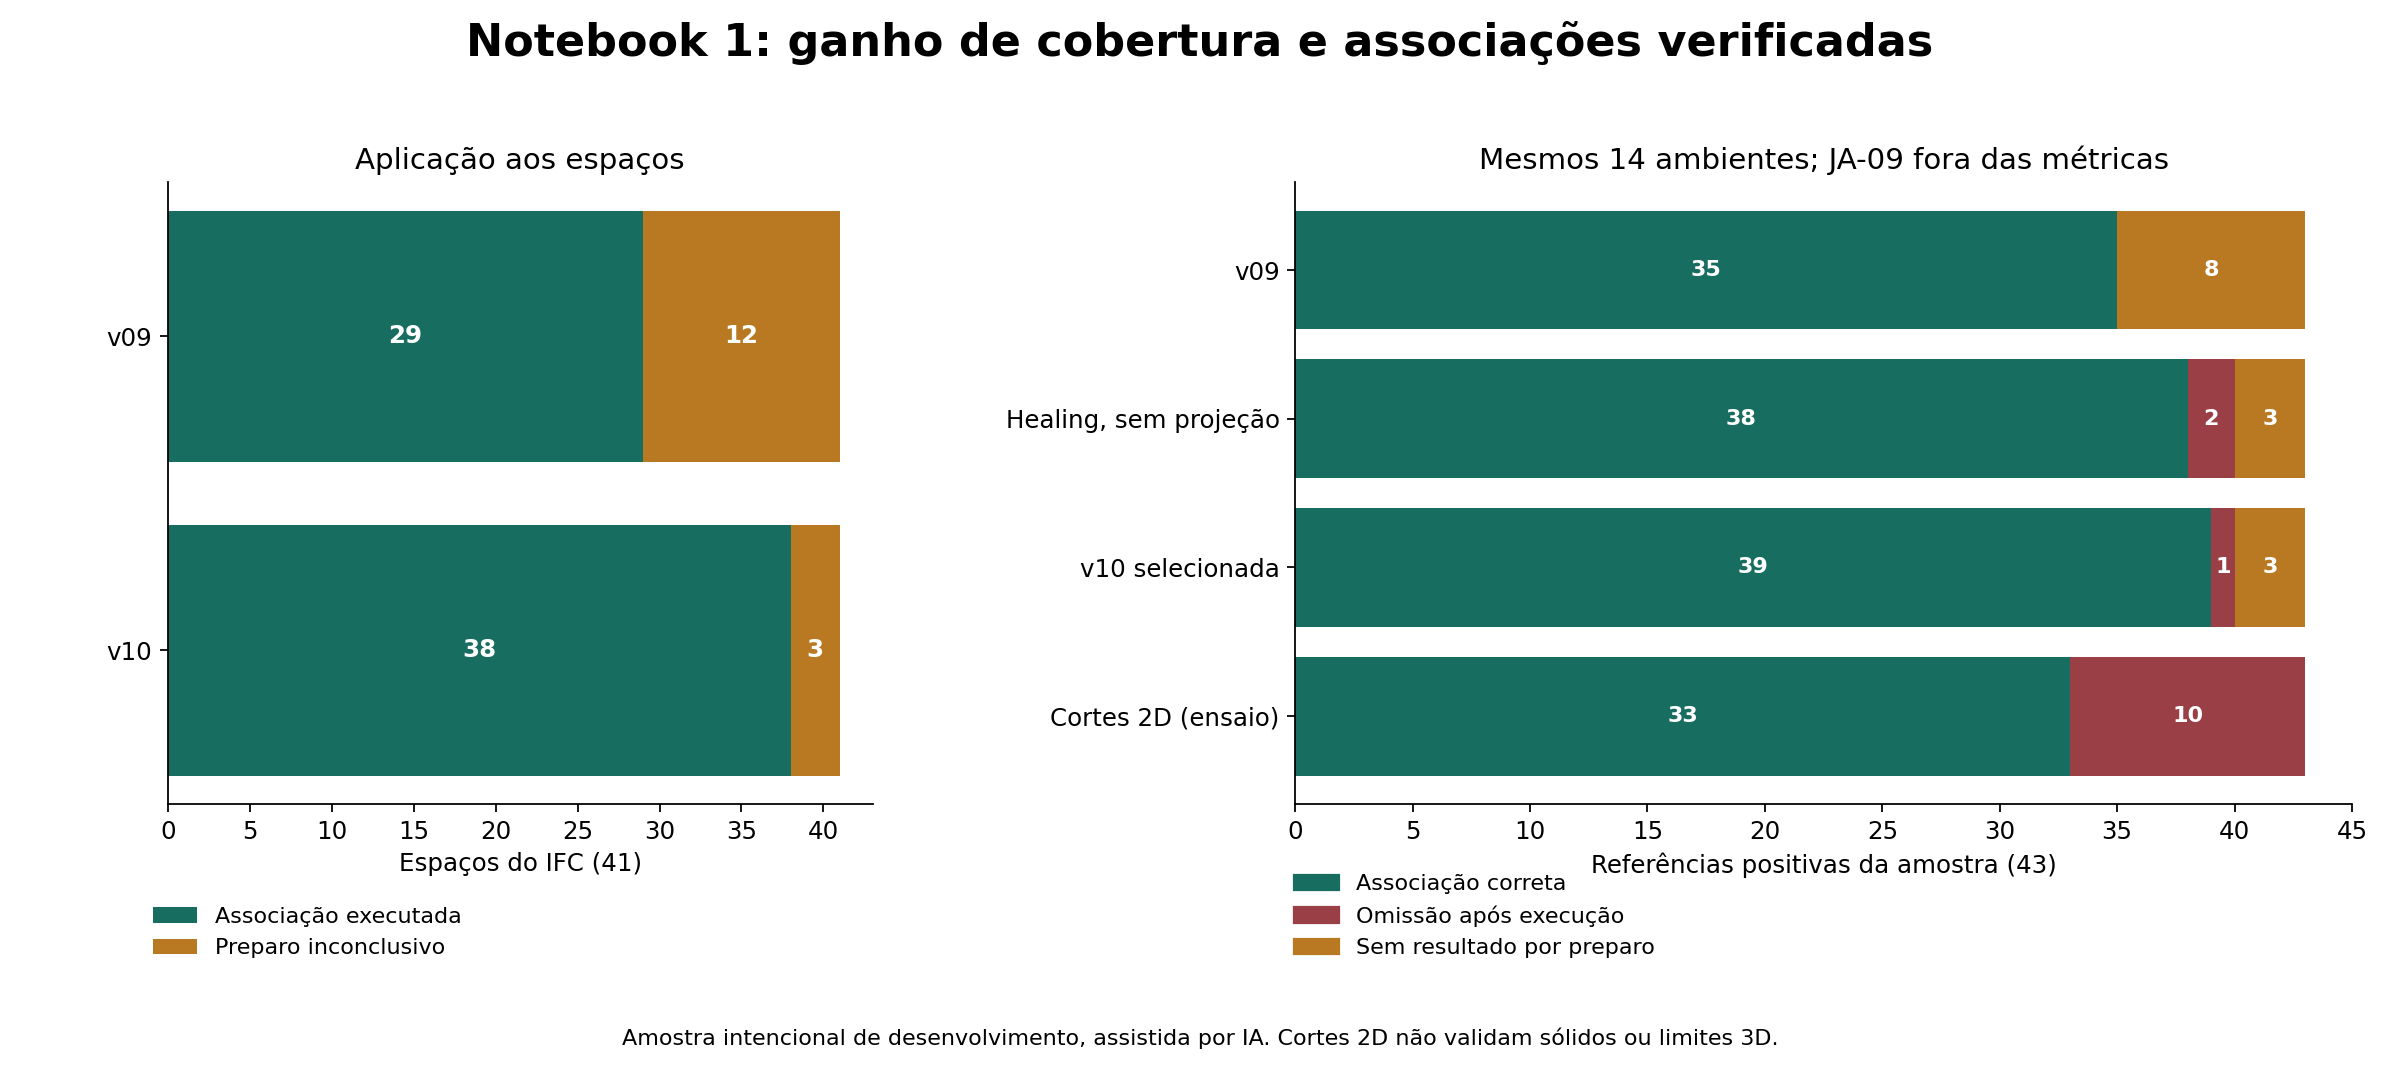

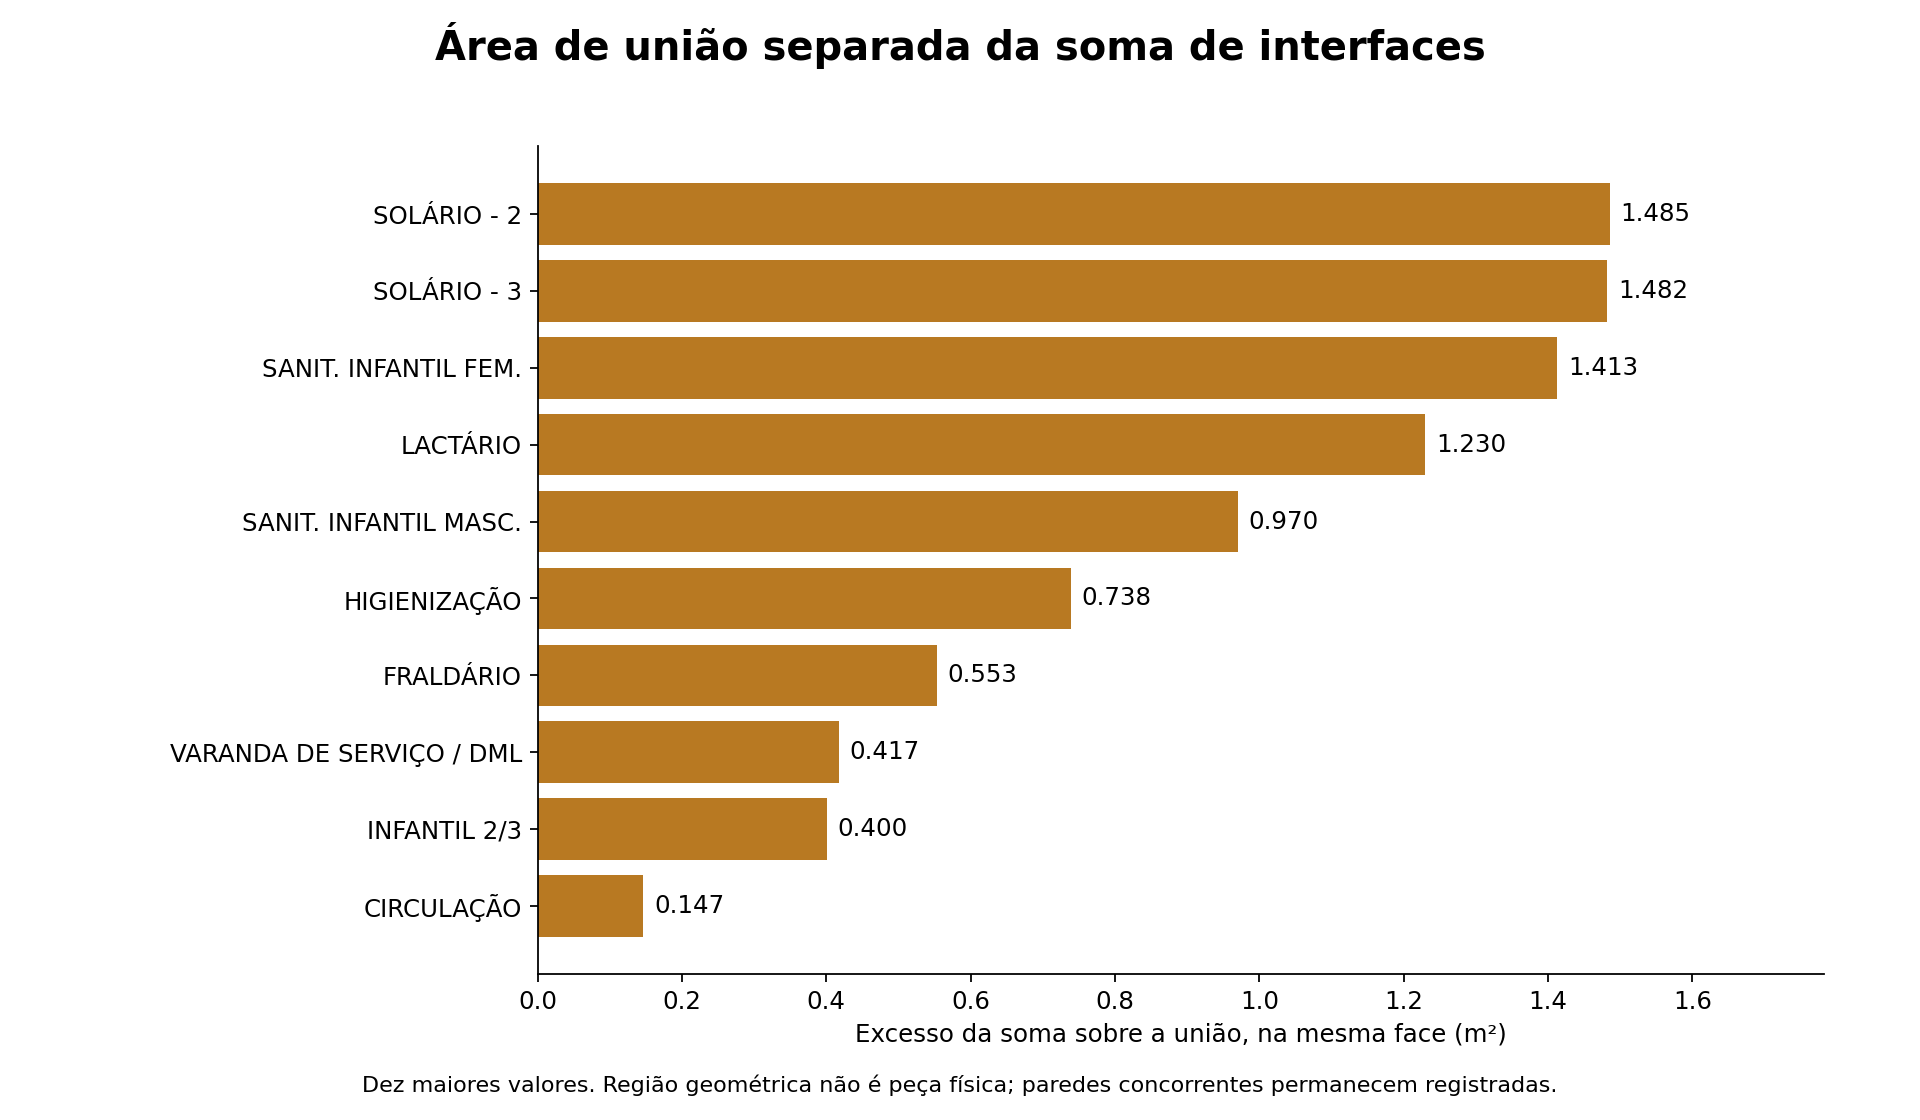

Relatório: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\aprimoramento_n1_v10\execucao_notebook\resultados\Relatorio_Literatura_e_Ensaios_v10.html


In [10]:
from apresentar_aprimoramento import run as apresentar
from IPython.display import display,Image
apresentar(SAIDA,REF,ENTRADA)
display(Image(filename=str(SAIDA/'figuras/Comparacao_Cobertura_e_Acertos_v10.png')))
display(Image(filename=str(SAIDA/'figuras/Sobreposicao_das_Interfaces_v10.png')))
print('Relatório:',SAIDA/'Relatorio_Literatura_e_Ensaios_v10.html')


## 11. Conclusão e integridade

**Há ganho efetivo:** 29 → 38 espaços com associação; preservação dos 74 pares anteriores; 101 pares totais; positivos confirmados na mesma referência 35 → 39. A recuperação, incluindo falhas de preparo, passou de **81,4% para 90,7%**. O ensaio 2D foi rejeitado como substituto, pois trouxe menos positivos apesar dos contornos em todos os espaços.

**Limitações preservadas:** Infantil 1, Infantil 5 e Amamentação continuam inconclusivos; JA-04 da Administração permanece omissão primária e candidato com folga de aproximadamente 10 mm; JA-09 continua indeterminada documentalmente. Há 23 pares de espaços sobrepostos e hospedeiros concorrentes em 28 espaços. Nos 27 candidatos internos, não houve confirmação volumétrica por falta de operandos adequados. Recortes fora do contorno parental continuam recusados.

Dos 38 espaços, 32 chegaram à associação sem pendências registradas nesse recorte e seis com pendências. Esses estados não significam completude arquitetônica. A avaliação documental é uma amostra de desenvolvimento, intencional e assistida por IA; não houve revisão independente ou outro edifício. Não se declara validação de todas as 101 associações/3.011 interfaces nem ganho de velocidade geral.

**Reprodução:** o preparo global foi executado nesta revisão e reutilizado aqui por hash, com código e opção de reexecução. Estas células refazem operadores, predição, ablação, ensaio 2D, auditorias, comparação, integração, consulta e SHACL em um novo kernel. A conversão semântica e o grafo anteriores são reutilizados explicitamente. Licenças e papéis de cada fonte permanecem no pacote.

In [11]:
assert sha(IFC)==IFC_SHA
assert all(sha(RAIZ/'codigo'/r['arquivo'])==r['sha256'] for r in fontes['arquivos'])
assert all(sha(REF/r['arquivo'])==r['sha256'] for r in fontes['referencias'])
total=sum(r['aprovados'] for r in [c1,c2,c3,c4,c5])+sum(regressao.values())+c6['aprovados']+comparacao['aprovados']
assert total==106
versoes={'python':sys.version,'numpy':numpy.__version__,'ifcopenshell':ifcopenshell.version,'OCP':OCP.__version__,'shapely':shapely.__version__,'rdflib':rdflib.__version__,'matplotlib':matplotlib.__version__,'pyshacl':pyshacl.__version__}
verificacao={'snapshot':SNAPSHOT,'ifc_preservado':True,'controles_aprovados':total,'lote':lote,'conferencia':conferencia,'comparacao':comparacao,'integracao':integracao,'shacl':validacao,'preparo_reexecutado_nestas_celulas':REPROCESSAR_PREPARO,'ablacao_reexecutada':EXECUTAR_ABLACAO,'versoes':versoes,'avaliacao_cega_ou_externa':False}
(SAIDA/'Verificacao_Final_v10.json').write_text(json.dumps(verificacao,ensure_ascii=False,indent=2),encoding='utf8')
print('APROVADO: 106 controles; 38 espaços com associação e três inconclusivos; 101 pares; grafo reaberto, consultado e validado com SHACL.')
print('Resultado limitado ao mesmo IFC e à amostra documental de desenvolvimento.')


APROVADO: 106 controles; 38 espaços com associação e três inconclusivos; 101 pares; grafo reaberto, consultado e validado com SHACL.
Resultado limitado ao mesmo IFC e à amostra documental de desenvolvimento.
